In [1]:
import planet
import geopandas as gpd
import shapely
import numpy as np
import json
import requests
import datetime
import ee
import geemap
# ee.Authenticate()
# ee.Initialize()
import ipyleaflet
import rasterio
import matplotlib.pyplot as plt
from planet import data_filter

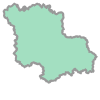

In [2]:

gdf=gpd.read_file('../../data/DISTRICT2011.shp')

jodhpur= gdf[gdf['NAME']=='Jodhpur']
jodhpur['geometry'].values[0]


<Axes: >

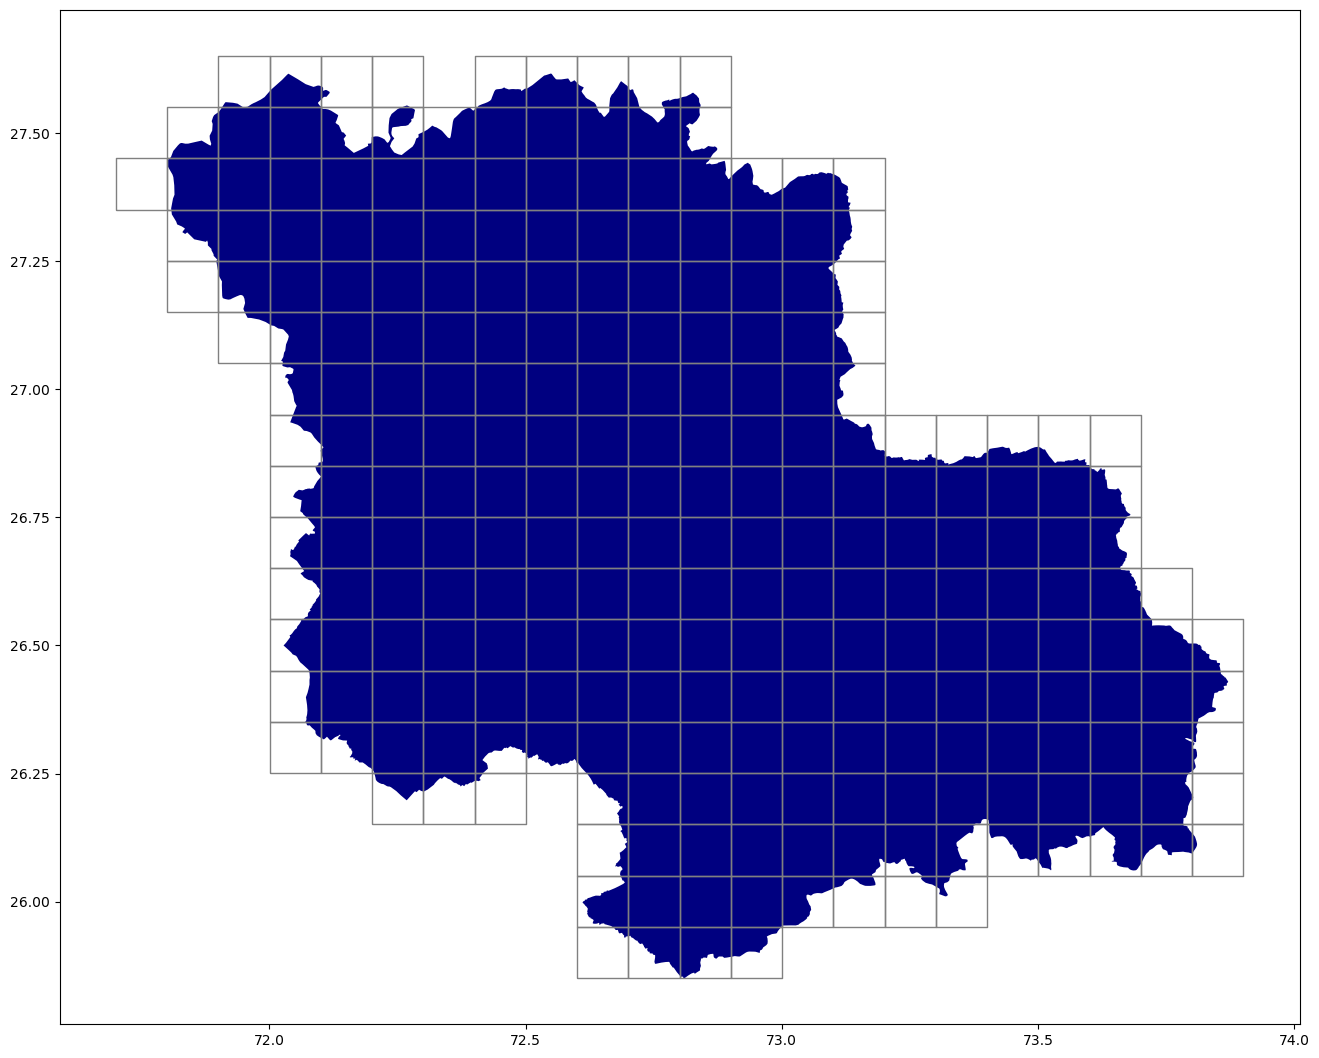

In [9]:
ax = jodhpur.plot(markersize=.1, figsize=(16, 16), cmap='jet')

xmin, ymin, xmax, ymax= jodhpur.total_bounds

## real cell dimensions
cell_width  = 0.1
cell_height = 0.1

grid_cells_jodhpur = []
for x0 in np.arange(xmin, xmax+cell_width, cell_width ):
    for y0 in np.arange(ymin, ymax+cell_height, cell_height):
        x1 = x0-cell_width
        y1 = y0+cell_height
        new_cell = shapely.geometry.box(x0, y0, x1, y1)
        if new_cell.intersects(jodhpur['geometry'].values[0]):
            grid_cells_jodhpur.append(new_cell)
        else:
            pass
        
cell_df_jodhpur = gpd.GeoDataFrame(grid_cells_jodhpur, columns=['geometry'])
cell_df_jodhpur.plot(ax=ax,facecolor="none", edgecolor='grey')



In [10]:
cell_df_jodhpur['geojson'] = [shapely.to_geojson(cell_df_jodhpur['geometry'].values[d]) for d in cell_df_jodhpur.index]
cell_df_jodhpur



,geometry,geojson
0,"POLYGON ((71.70067 27.35067, 71.70067 27.45067...","{""type"":""Polygon"",""coordinates"":[[[71.70066692..."
1,"POLYGON ((71.80067 27.15067, 71.80067 27.25067...","{""type"":""Polygon"",""coordinates"":[[[71.80066692..."
2,"POLYGON ((71.80067 27.25067, 71.80067 27.35067...","{""type"":""Polygon"",""coordinates"":[[[71.80066692..."
3,"POLYGON ((71.80067 27.35067, 71.80067 27.45067...","{""type"":""Polygon"",""coordinates"":[[[71.80066692..."
4,"POLYGON ((71.80067 27.45067, 71.80067 27.55067...","{""type"":""Polygon"",""coordinates"":[[[71.80066692..."
...,...,...
250,"POLYGON ((73.80067 26.05067, 73.80067 26.15067...","{""type"":""Polygon"",""coordinates"":[[[73.80066691..."
251,"POLYGON ((73.80067 26.15067, 73.80067 26.25067...","{""type"":""Polygon"",""coordinates"":[[[73.80066691..."
252,"POLYGON ((73.80067 26.25067, 73.80067 26.35067...","{""type"":""Polygon"",""coordinates"":[[[73.80066691..."
253,"POLYGON ((73.80067 26.35067, 73.80067 26.45067...","{""type"":""Polygon"",""coordinates"":[[[73.80066691..."


In [11]:
async def search(session, geometry, toi_start, toi_end, item_type):  
    # Initialize the Data API client so we can search for scenes:
    cl_data = session.client("data")


    # Create search filter based on the user's filter parameters:
    search_filter = data_filter.and_filter(
       [
           data_filter.date_range_filter("acquired", gte=toi_start, lte=toi_end),
           data_filter.geometry_filter(geometry),
       ]
    )
        # Search for filtered asset ids:
    # I set the limit to 0, to make sure all scenes are returned.

    ids = [i["id"] async for i in cl_data.search([item_type], search_filter, limit=0)]


    print(
       f"""{len(ids)} scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range."""
    )

    return ids


In [12]:
toi_start= datetime.datetime(2023,3,1)
toi_end= datetime.datetime(2023,6,30)


item_type = "SkySatScene"

session = planet.Session()
heatmap=[]
info_city=[]
for i in cell_df_jodhpur.index:
    print(f'{i}/{len(cell_df_jodhpur)}')
    geometry=json.loads(cell_df_jodhpur['geojson'].values[i])
    async with planet.Session() as sess:
        ids = await search(sess, geometry, toi_start, toi_end, item_type)
    info_city.append(ids)
    heatmap.append(len(ids))


cell_df_jodhpur['info_city']=info_city
cell_df_jodhpur['heatmap']=heatmap

# cell_df_jaipur.to_file('jaipur_data.shp')

0/255
0 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
1/255
0 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
2/255
0 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
3/255
0 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
4/255
0 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
5/255
0 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
6/255
0 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
7/255
0 scenes were found. If this number seems too high,
               narrow down your search by using a sho

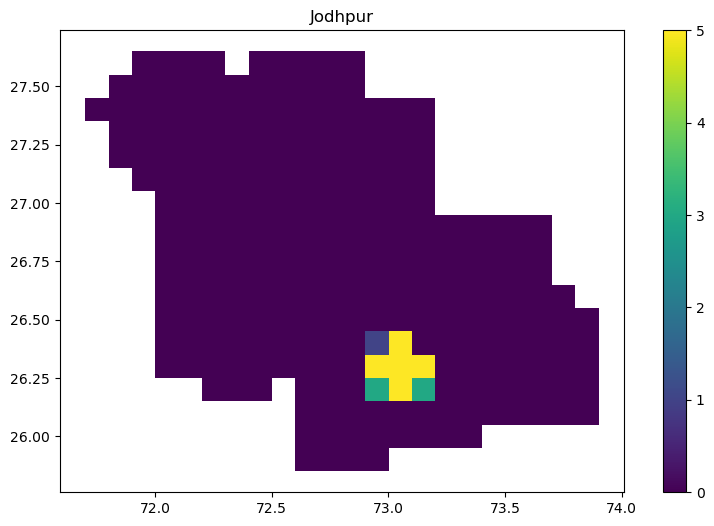

In [13]:
# Plot the 'heatmap' column of dataframe
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
cax = cell_df_jodhpur.plot(column='heatmap', ax=ax, vmin=0, vmax=5, legend=True)

# Set a title
ax.set_title('Jodhpur')

plt.show()


In [14]:
cell_df_jodhpur

,geometry,geojson,info_city,heatmap
0,"POLYGON ((71.70067 27.35067, 71.70067 27.45067...","{""type"":""Polygon"",""coordinates"":[[[71.70066692...",[],0
1,"POLYGON ((71.80067 27.15067, 71.80067 27.25067...","{""type"":""Polygon"",""coordinates"":[[[71.80066692...",[],0
2,"POLYGON ((71.80067 27.25067, 71.80067 27.35067...","{""type"":""Polygon"",""coordinates"":[[[71.80066692...",[],0
3,"POLYGON ((71.80067 27.35067, 71.80067 27.45067...","{""type"":""Polygon"",""coordinates"":[[[71.80066692...",[],0
4,"POLYGON ((71.80067 27.45067, 71.80067 27.55067...","{""type"":""Polygon"",""coordinates"":[[[71.80066692...",[],0
...,...,...,...,...
250,"POLYGON ((73.80067 26.05067, 73.80067 26.15067...","{""type"":""Polygon"",""coordinates"":[[[73.80066691...",[],0
251,"POLYGON ((73.80067 26.15067, 73.80067 26.25067...","{""type"":""Polygon"",""coordinates"":[[[73.80066691...",[],0
252,"POLYGON ((73.80067 26.25067, 73.80067 26.35067...","{""type"":""Polygon"",""coordinates"":[[[73.80066691...",[],0
253,"POLYGON ((73.80067 26.35067, 73.80067 26.45067...","{""type"":""Polygon"",""coordinates"":[[[73.80066691...",[],0


In [15]:
info_city

[[],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 [],
 ['20230307_090650_ssc7d3_0018',
  '20230307_090650_ssc7d3_0017',
  '20230307_090650_ssc7d3_0016'],
 ['20230307_090650_ssc7d3_0016',
  '20230307_090650_ssc7d3_0015',
  '20230307_090650_ssc7d3_0014',
  '20230307_090650_ssc7d3_0013'